In [ ]:
!pip install scikit-image

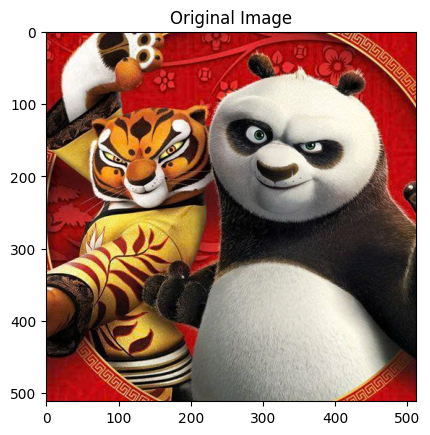

In [ ]:
import cv2
import numpy as np
from skimage.exposure import rescale_intensity
import matplotlib.pyplot as plt

# Tải ảnh vào Colab
image_path = '/content/panda.jpg'
image = cv2.imread(image_path)

# Hiển thị ảnh gốc
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Chuyển từ BGR sang RGB
plt.imshow(image_rgb)
plt.title("Original Image")
plt.show()


# Lab 1: Làm mờ vùng nhỏ trên ảnh


## 1. Hàm `convolve`

Hàm `convolve` thực hiện phép tích chập (convolution) giữa ảnh đầu vào và kernel. Dưới đây là các bước chi tiết:

### 1.1. Xác định kích thước ảnh và kernel
- Kích thước ảnh đầu vào: `(ih, iw)` là chiều cao và chiều rộng của ảnh.
- Kích thước kernel: `(kh, kw)` là chiều cao và chiều rộng của kernel.

### 1.2. Thêm padding vào ảnh
- Để đảm bảo  kích thước ảnh đầu ra giống với kích thước ảnh đầu vào, chúng ta thêm padding vào ảnh. Số lượng padding được tính bằng:
  $$
  \text{pad} = \frac{\text{kw} - 1}{2}
  $$
-  sử dụng hàm `cv2.copyMakeBorder` với chế độ `cv2.BORDER_REPLICATE`.

### 1.3. Khởi tạo ma trận đầu ra
- Ma trận đầu ra `output` được khởi tạo với kích thước `(ih, iw)` và kiểu dữ liệu là `float32`.

### 1.4. Thực hiện phép tích chập
- Với mỗi pixel `(y, x)` trong ảnh (không tính phần padding), chúng ta thực hiện phép tích chập bằng cách lấy vùng quan tâm (ROI) xung quanh pixel đó và nhân với kernel:
$$
  \
  \text{roi} = \text{image}[y - \text{pad}:y + \text{pad} + 1, x - \text{pad}:x + \text{pad} + 1]
  \
  $$

$$
  \
  k = \sum_{i=0}^{\text{kh}-1} \sum_{j=0}^{\text{kw}-1} \text{roi}[i, j] \times \text{kernel}[i, j]
  \$$

- Kết quả được lưu vào ma trận đầu ra:
$$
  \
  \text{output}[y - \text{pad}, x - \text{pad}] = k
  \
  $$

### 1.5. Chuẩn hóa giá trị đầu ra
- Ma trận đầu ra được chuẩn hóa về khoảng giá trị `[0, 255]` bằng hàm `rescale_intensity`.
$$
  \
  \text{output} = (\text{output} \times 255)
  \
$$


## 2. Tạo kernel small blur
- Kernel small blur được tạo bằng cách khởi tạo một ma trận `7x7` với giá trị `1.0 / (7 * 7)`:
  $$
  \
  \text{Kernel_Blur} = \frac{1}{49} \times \begin{bmatrix}
  1 & 1 & \cdots & 1 \\
  1 & 1 & \cdots & 1 \\
  \vdots & \vdots & \ddots & \vdots \\
  1 & 1 & \cdots & 1
  \end{bmatrix}
  \
  $$



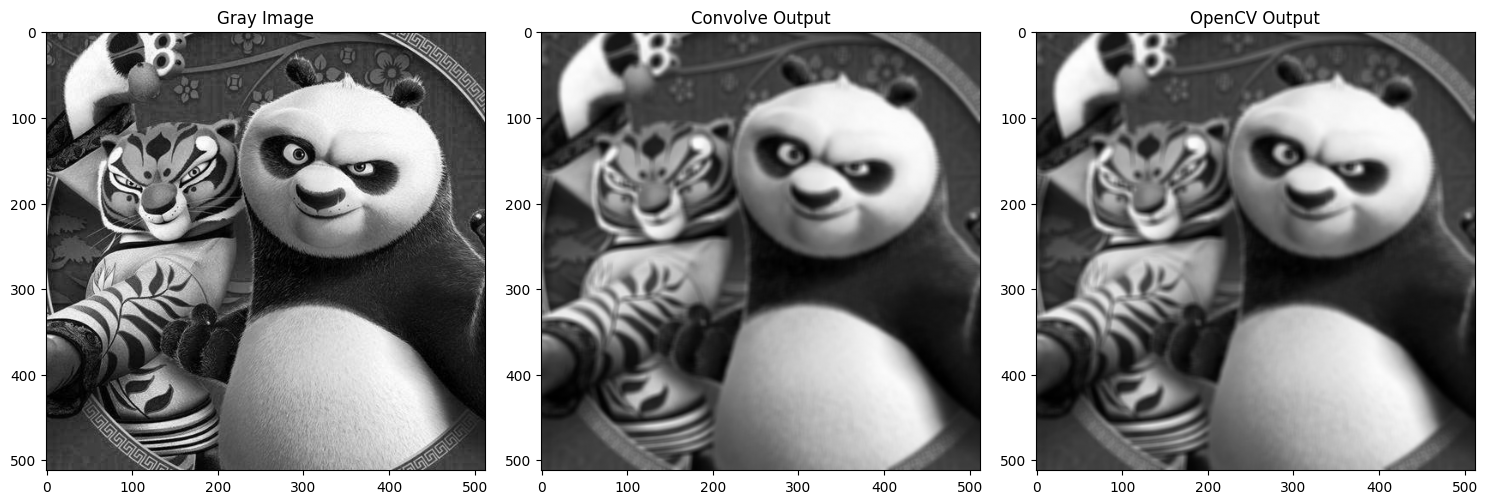

In [ ]:
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
import numpy as np
import cv2

def convolve(image, kernel):
    ih, iw = image.shape
    kh, kw = kernel.shape
    pad = (kw -1)//2

    image = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
    output = np.zeros((ih, iw), dtype="float32")

    for y in range(pad, ih+pad):
      for x in range(pad, iw+pad):
        roi = image[y-pad:y+pad+1, x-pad:x+pad+1]
        k = (roi * kernel).sum()
        output[y-pad, x-pad] = k
    output = rescale_intensity(output, in_range=(0, 255))
    output = (output * 255).astype("uint8")

    return output

# Đọc ảnh
image = cv2.imread('/content/panda.jpg')
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Kernel small blur
blurred_kernel = np.ones((7,7), dtype="float32")*(1.0/(7*7))

# Áp dụng kernel small blur
blurred = convolve(gray,blurred_kernel)
opencvOutput = cv2.filter2D(gray, -1, blurred_kernel)
# Hiển thị 3 ảnh với tiêu đề riêng
plt.figure(figsize=(15, 5))

# Ảnh xám
plt.subplot(1, 3, 1)  # 1 hàng, 3 cột, vị trí 1
plt.imshow(gray, cmap='gray')
plt.title("Gray Image")

# Ảnh sau khi tích chập tự tính tay
plt.subplot(1, 3, 2)  # 1 hàng, 3 cột, vị trí 2
plt.imshow(blurred, cmap='gray')
plt.title("Convolve Output")

# Ảnh sau khi tích chập bằng OpenCV
plt.subplot(1, 3, 3)  # 1 hàng, 3 cột, vị trí 3
plt.imshow(opencvOutput, cmap='gray')
plt.title("OpenCV Output")

plt.tight_layout()
plt.show()

# Bộ lọc Sharpen (Làm sắc nét)
Bộ lọc sharpen trong mã của bạn được định nghĩa như sau:

Bộ lọc này có kích thước 3x3 và được thiết kế để tăng cường độ tương phản của các cạnh và chi tiết trong ảnh. Cụ thể:
- Giá trị trung tâm của bộ lọc là 5, điều này làm tăng giá trị của pixel trung tâm.
- Các giá trị xung quanh là -1, điều này làm giảm giá trị của các pixel lân cận.

Khi áp dụng bộ lọc này, pixel trung tâm sẽ được tăng cường, trong khi các pixel xung quanh bị giảm đi, tạo ra hiệu ứng làm sắc nét.

#  Ví dụ tính toán bằng tay
Giả sử bạn có một phần của ảnh (ma trận 3x3) như sau:

$$
I =
\begin{bmatrix}
100 & 120 & 110 \\
115 & 130 & 125 \\
105 & 110 & 100
\end{bmatrix}
$$

Áp dụng bộ lọc sharpen:

$$
K =
\begin{bmatrix}
0 & -1 & 0 \\
-1 & 5 & -1 \\
0 & -1 & 0
\end{bmatrix}
$$

Giá trị pixel trung tâm mới được tính như sau:

$$
O(1,1) = (100 \cdot 0) + (120 \cdot -1) + (110 \cdot 0) + (115 \cdot -1) + (130 \cdot 5) + (125 \cdot -1) + (105 \cdot 0) + (110 \cdot -1) + (100 \cdot 0)
$$

$$
O(1,1) = 0 - 120 + 0 - 115 + 650 - 125 + 0 - 110 + 0
$$

$$
O(1,1) = 650 - 120 - 115 - 125 - 110 = 180
$$

Sau khi tính toán, giá trị pixel trung tâm mới là **180**, cao hơn giá trị ban đầu (**130**), làm tăng độ tương phản và làm sắc nét ảnh.

# 5. Quy trình áp dụng bộ lọc
- **Padding:** Để đảm bảo kích thước ảnh đầu ra giống với ảnh đầu vào, ảnh được đệm thêm các pixel xung quanh (thường là sao chép giá trị pixel biên).
- **Duyệt qua từng pixel:** Bộ lọc được di chuyển qua từng pixel của ảnh.
- **Tính toán giá trị mới:** Tại mỗi vị trí, giá trị pixel mới được tính bằng cách nhân từng phần tử của bộ lọc với các pixel tương ứng trên ảnh và cộng lại.
- **Chuẩn hóa giá trị:** Giá trị đầu ra được chuẩn hóa về khoảng [0, 255] để đảm bảo nó nằm trong phạm vi giá trị pixel hợp lệ.

# 6. Kết quả của bộ lọc sharpen
Bộ lọc sharpen làm tăng độ tương phản của các cạnh và chi tiết trong ảnh.
- Các vùng có sự thay đổi đột ngột về cường độ (như biên) sẽ trở nên rõ ràng hơn.
- Ảnh đầu ra sẽ trông sắc nét hơn so với ảnh gốc.


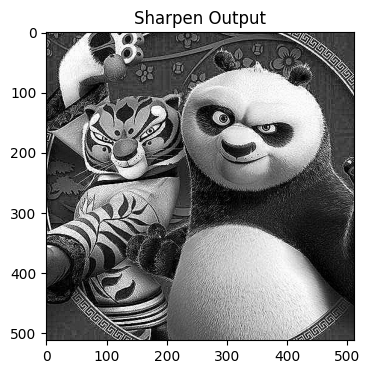

In [ ]:
# Bộ lọc sharpen
sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype="int")
sharpen_output = convolve(gray, sharpen)


# Hiển thị kết quả
plt.figure(figsize=(6,4))

plt.subplot(1,1,1)
plt.imshow(sharpen_output, cmap='gray')
plt.title('Sharpen Output')
plt.show()


# Bộ lọc Laplacian (Phát hiện biên)

Bộ lọc Laplacian là một bộ lọc được sử dụng để phát hiện biên (edges) trong ảnh. Nó hoạt động bằng cách tính toán đạo hàm bậc hai của ảnh, giúp làm nổi bật các vùng có sự thay đổi đột ngột về cường độ pixel (ví dụ: biên giữa các đối tượng).

## Công thức toán học của bộ lọc Laplacian
Bộ lọc Laplacian thường được biểu diễn dưới dạng một ma trận 3x3 như sau:

$$
K =
\begin{bmatrix}
0 & 1 & 0 \\
1 & -4 & 1 \\
0 & 1 & 0
\end{bmatrix}
$$


Trong đó:
- Giá trị trung tâm của bộ lọc là -4, đại diện cho trọng số của pixel trung tâm.
- Các giá trị xung quanh là 1, đại diện cho trọng số của các pixel lân cận.

## Công thức tích chập (Convolution)
Khi áp dụng bộ lọc Laplacian lên ảnh, giá trị của pixel tại vị trí $$ (i, j) $$ trên ảnh đầu ra $$ O $$ được tính bằng công thức tích chập:

$$
O(i,j) = \sum_{m=0}^{2} \sum_{n=0}^{2} I(i+m-1,j+n-1) \cdot K(m,n)
$$


Trong đó:
- $$ I $$ là ma trận ảnh đầu vào.
- $$ K $$ là bộ lọc Laplacian.
- $$ I(i+m-1,j+n-1) $$ là giá trị pixel của ảnh đầu vào tại vị trí $$ (i+m-1,j+n-1) $$.
- $$ K(m,n) $$ là giá trị của bộ lọc tại vị trí $$ (m,n) $$.

## Ví dụ tính toán bằng tay
Giả sử bạn có một phần của ảnh (ma trận 3x3) như sau:

$$
I =
\begin{bmatrix}
100 & 120 & 110 \\
115 & 130 & 125 \\
105 & 110 & 100
\end{bmatrix}
$$


Áp dụng bộ lọc Laplacian:

$$
K =
\begin{bmatrix}
0 & 1 & 0 \\
1 & -4 & 1 \\
0 & 1 & 0
\end{bmatrix}
$$


Giá trị pixel trung tâm mới được tính như sau:

$$
O(1,1) = (100 \cdot 0) + (120 \cdot 1) + (110 \cdot 0) + (115 \cdot 1) + (130 \cdot -4) + (125 \cdot 1) + (105 \cdot 0) + (110 \cdot 1) + (100 \cdot 0)
$$


$$
O(1,1) = 0 + 120 + 0 + 115 - 520 + 125 + 0 + 110 + 0
$$


$$
O(1,1) = 120 + 115 - 520 + 125 + 110 = -50
$$


Sau khi tính toán, giá trị pixel trung tâm mới là **-50**. Giá trị này có thể âm hoặc dương, tùy thuộc vào sự thay đổi cường độ pixel trong ảnh.

## Chuẩn hóa giá trị đầu ra
Vì kết quả tích chập có thể nằm ngoài phạm vi [0, 255], chúng ta cần chuẩn hóa giá trị đầu ra về khoảng này để hiển thị ảnh. Công thức chuẩn hóa:

$$
O_{\text{normalized}} = \text{rescale\_intensity}(O, in\_range=(0,255))
$$


##  Kết quả của bộ lọc Laplacian
Bộ lọc Laplacian làm nổi bật các biên và chi tiết trong ảnh.
- Các vùng có sự thay đổi đột ngột về cường độ pixel (ví dụ: biên giữa các đối tượng) sẽ có giá trị lớn hơn.
- Ảnh đầu ra thường có nền tối và các biên sáng.


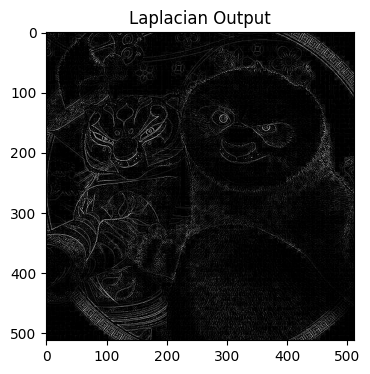

In [ ]:
# Bộ lọc Laplacian
laplacian = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
], dtype="int")
laplacian_output = convolve(gray, laplacian)


# Hiển thị kết quả
plt.figure(figsize=(6,4))

plt.subplot(1,1,1)
plt.imshow(laplacian_output, cmap='gray')
plt.title('Laplacian Output')
plt.show()


## Bộ lọc Sobel X (Phát hiện biên theo chiều ngang)

Bộ lọc Sobel X là một bộ lọc được sử dụng để phát hiện biên (edges) theo chiều ngang (trục x) trong ảnh. Nó hoạt động bằng cách tính toán đạo hàm bậc nhất của ảnh theo chiều ngang, giúp làm nổi bật các biên dọc (thay đổi cường độ pixel theo chiều ngang).

##Công thức toán học của bộ lọc Sobel X

Bộ lọc Sobel X thường được biểu diễn dưới dạng một ma trận 3x3 như sau:

$$
K =
\begin{bmatrix}
-1 & 0 & 1 \\
-2 & 0 & 2 \\
-1 & 0 & 1
\end{bmatrix}
$$


Trong đó:
- Các giá trị âm và dương ở hai bên của ma trận giúp tính toán sự thay đổi cường độ pixel theo chiều ngang.
- Giá trị trung tâm của bộ lọc là 0, vì nó không ảnh hưởng đến pixel trung tâm.

# Công thức tích chập (Convolution)

Khi áp dụng bộ lọc Sobel X lên ảnh, giá trị của pixel tại vị trí $$(i,j)$$ trên ảnh đầu ra $$O$$ được tính bằng công thức tích chập:

$$
O(i,j) = \sum_{m=0}^2 \sum_{n=0}^2 I(i+m-1,j+n-1) \cdot K(m,n)
$$


Trong đó:
- $$I$$ là ma trận ảnh đầu vào.
- $$K$$ là bộ lọc Sobel X.
- $$I(i+m-1,j+n-1)$$ là giá trị pixel của ảnh đầu vào tại vị trí $$(i+m-1,j+n-1)$$.
- $$K(m,n)$$ là giá trị của bộ lọc tại vị trí $$(m,n)$$.

# Ví dụ tính toán bằng tay

Giả sử bạn có một phần của ảnh (ma trận 3x3) như sau:

$$
I =
\begin{bmatrix}
100 & 120 & 110 \\
115 & 130 & 125 \\
105 & 110 & 100
\end{bmatrix}
$$


Áp dụng bộ lọc Sobel X:

$$
K =
\begin{bmatrix}
-1 & 0 & 1 \\
-2 & 0 & 2 \\
-1 & 0 & 1
\end{bmatrix}
$$


Giá trị pixel trung tâm mới được tính như sau:

$$
O(1,1) = (100 \cdot -1) + (120 \cdot 0) + (110 \cdot 1) + (115 \cdot -2) + (130 \cdot 0) + (125 \cdot 2) + (105 \cdot -1) + (110 \cdot 0) + (100 \cdot 1)
$$


$$
O(1,1) = -100 + 0 + 110 - 230 + 0 + 250 - 105 + 0 + 100
$$


$$
O(1,1) = -100 + 110 - 230 + 250 - 105 + 100 = 25
$$


Sau khi tính toán, giá trị pixel trung tâm mới là **25**. Giá trị này phản ánh sự thay đổi cường độ pixel theo chiều ngang.

# Chuẩn hóa giá trị đầu ra

Vì kết quả tích chập có thể nằm ngoài phạm vi [0, 255], chúng ta cần chuẩn hóa giá trị đầu ra về khoảng này để hiển thị ảnh. Công thức chuẩn hóa:

$$
O_{normalized} = \text{rescale\_intensity}(O, in\_range=(0,255))
$$


# Kết quả của bộ lọc Sobel X

- Bộ lọc Sobel X làm nổi bật các biên theo chiều ngang trong ảnh.
- Các vùng có sự thay đổi đột ngột về cường độ pixel theo chiều ngang (ví dụ: biên dọc) sẽ có giá trị lớn hơn.
- Ảnh đầu ra thường có nền tối và các biên ngang sáng.


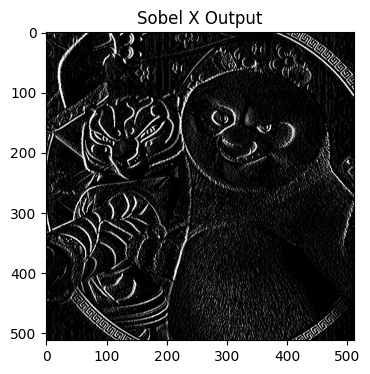

In [ ]:
# Bộ lọc Sobel X
sobelX = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype="int")
sobelX_output = convolve(gray, sobelX)


# Hiển thị kết quả
plt.figure(figsize=(6,4))

plt.subplot(1,1,1)
plt.imshow(sobelX_output, cmap='gray')
plt.title('Sobel X Output')
plt.show()


Bộ lọc Sobel Y (Phát hiện biên theo chiều dọc)

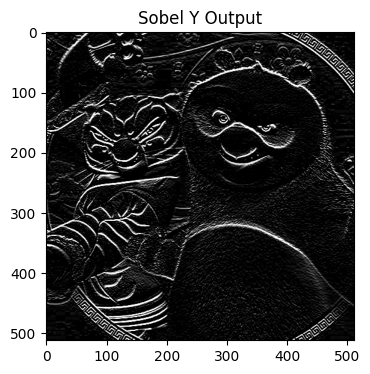

In [ ]:
# Bộ lọc Sobel Y
sobelY = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
], dtype="int")
sobelY_output = convolve(gray, sobelY)

# Hiển thị kết quả
plt.figure(figsize=(6,4))

plt.subplot(1,1,1)
plt.imshow(sobelY_output, cmap='gray')
plt.title('Sobel Y Output')
plt.show()


Bộ lọc Canny (Phát hiện biên)

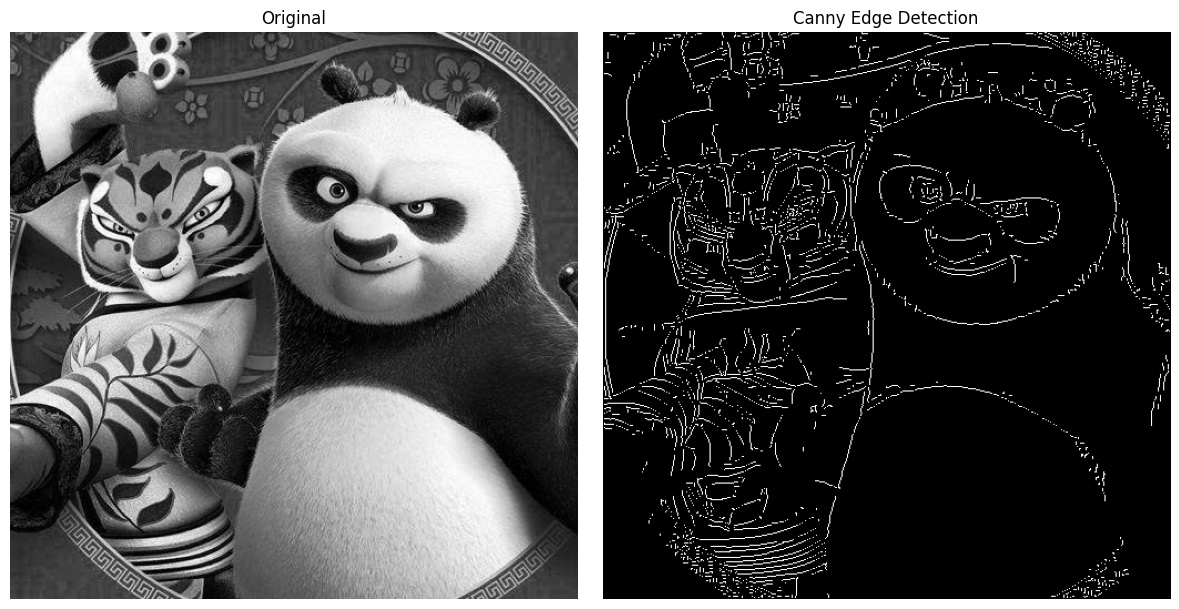

In [ ]:
def canny_edge_detection(image):
    # Chuyển ảnh sang xám trước khi áp dụng Canny
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()

    blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

    sobelx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)

    magnitude = np.hypot(sobelx, sobely)
    magnitude = magnitude / magnitude.max() * 255
    angle = np.arctan2(sobely, sobelx) * 180 / np.pi
    angle[angle < 0] += 180

    def non_max_suppression(mag, ang):
        H, W = mag.shape
        Z = np.zeros((H, W), dtype=np.uint8)
        angle = ang.copy()

        for i in range(1, H-1):
            for j in range(1, W-1):
                try:
                    q = 255
                    r = 255

                    # 0 độ
                    if (0 <= angle[i,j] < 22.5) or (157.5 <= angle[i,j] <= 180):
                        q = mag[i, j+1]
                        r = mag[i, j-1]
                    # 45 độ
                    elif (22.5 <= angle[i,j] < 67.5):
                        q = mag[i+1, j-1]
                        r = mag[i-1, j+1]
                    # 90 độ
                    elif (67.5 <= angle[i,j] < 112.5):
                        q = mag[i+1, j]
                        r = mag[i-1, j]
                    # 135 độ
                    elif (112.5 <= angle[i,j] < 157.5):
                        q = mag[i-1, j-1]
                        r = mag[i+1, j+1]

                    if (mag[i,j] >= q) and (mag[i,j] >= r):
                        Z[i,j] = mag[i,j]
                    else:
                        Z[i,j] = 0
                except IndexError as e:
                    pass
        return Z

    suppressed = non_max_suppression(magnitude, angle)

    highThreshold = suppressed.max() * 0.2
    lowThreshold = highThreshold * 0.5

    strong = 255
    weak = 75

    result = np.zeros_like(suppressed, dtype=np.uint8)

    strong_i, strong_j = np.where(suppressed >= highThreshold)
    weak_i, weak_j = np.where((suppressed <= highThreshold) & (suppressed >= lowThreshold))

    result[strong_i, strong_j] = strong
    result[weak_i, weak_j] = weak

    def hysteresis(img):
        H, W = img.shape
        for i in range(1, H-1):
            for j in range(1, W-1):
                if img[i,j] == weak:
                    if ((img[i+1, j-1] == strong) or (img[i+1, j] == strong) or (img[i+1, j+1] == strong)
                        or (img[i, j-1] == strong) or (img[i, j+1] == strong)
                        or (img[i-1, j-1] == strong) or (img[i-1, j] == strong) or (img[i-1, j+1] == strong)):
                        img[i,j] = strong
                    else:
                        img[i,j] = 0
        return img

    edges = hysteresis(result)


    # Hiển thị kết quả
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(gray, cmap='gray')
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(edges, cmap='gray')
    plt.title("Canny Edge Detection")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

image = cv2.imread('/content/panda.jpg')
canny_edge_detection(image)


Sobel kết hợp Sobel X và Sobel Y

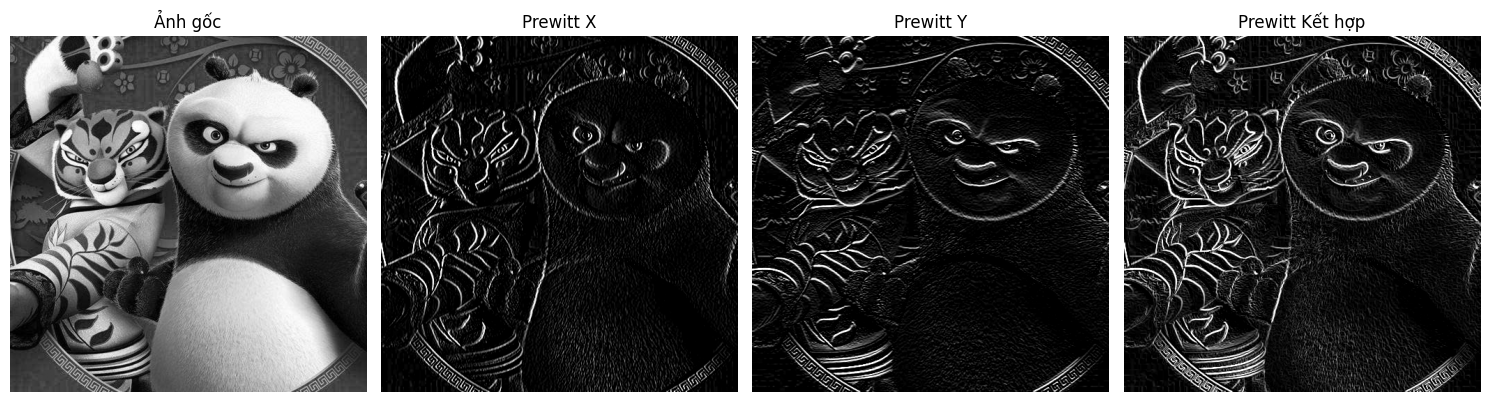

In [ ]:
def convolve(image, kernel):
    ih, iw = image.shape
    kh, kw = kernel.shape
    pad = (kw - 1) // 2
    image_padded = np.pad(image, pad, mode='edge')
    output = np.zeros((ih, iw), dtype=np.float32)

    for y in range(pad, ih + pad):
        for x in range(pad, iw + pad):
            roi = image_padded[y - pad:y + pad + 1, x - pad:x + pad + 1]
            output[y - pad, x - pad] = np.sum(roi * kernel)

    output = rescale_intensity(output, in_range=(0, 255))
    return (output * 255).astype("uint8")

# Bộ lọc Prewitt X (phát hiện biên theo chiều ngang)
prewittX = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype="int")

# Bộ lọc Prewitt Y (phát hiện biên theo chiều dọc)
prewittY = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [-1, -1, -1]
], dtype="int")

# Áp dụng bộ lọc Prewitt X
prewitt_x = convolve(gray, prewittX)

# Áp dụng bộ lọc Prewitt Y
prewitt_y = convolve(gray, prewittY)

# Kết hợp kết quả từ Prewitt X và Prewitt Y để phát hiện biên toàn diện
prewitt_combined = np.hypot(prewitt_x, prewitt_y)
prewitt_combined = rescale_intensity(prewitt_combined, in_range=(0, 255))
prewitt_combined = (prewitt_combined * 255).astype("uint8")

# Hiển thị kết quả
plt.figure(figsize=(15, 5))

# Ảnh gốc
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.title("Ảnh gốc")
plt.axis('off')

# Kết quả Prewitt X
plt.subplot(1, 4, 2)
plt.imshow(prewitt_x, cmap='gray')
plt.title("Prewitt X")
plt.axis('off')

# Kết quả Prewitt Y
plt.subplot(1, 4, 3)
plt.imshow(prewitt_y, cmap='gray')
plt.title("Prewitt Y")
plt.axis('off')

# Hiển thị kết quả kết hợp
plt.subplot(1, 4, 4)
plt.imshow(prewitt_combined, cmap='gray')
plt.title("Prewitt Kết hợp")
plt.axis('off')

plt.tight_layout()
plt.show()


Sobel kết hợp Sobel X và Sobel Y

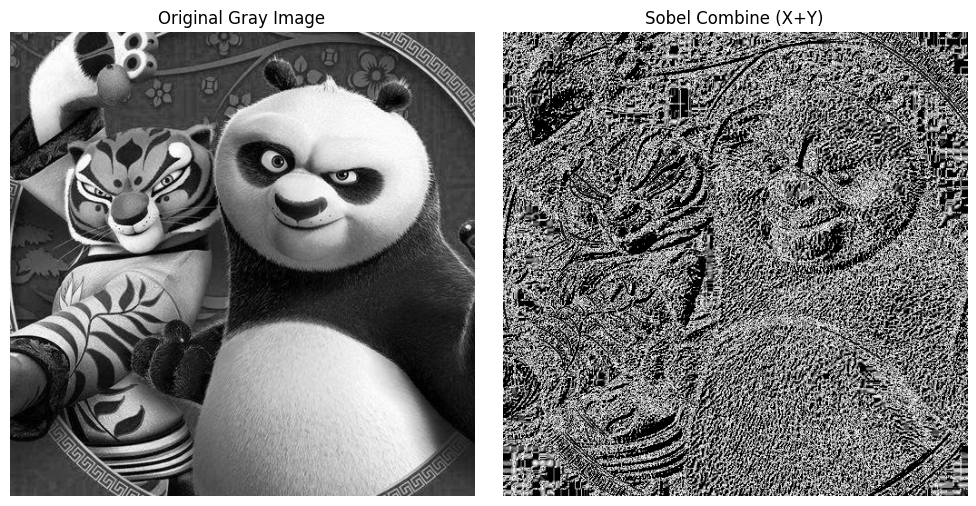

In [ ]:
def convolve(image, kernel):
    ih, iw = image.shape
    kh, kw = kernel.shape
    pad = (kw - 1) // 2

    image_padded = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REPLICATE)

    output = np.zeros((ih, iw), dtype="float32")

    for y in range(pad, ih + pad):
        for x in range(pad, iw + pad):
            roi = image_padded[y - pad:y + pad + 1, x - pad:x + pad + 1]
            output[y - pad, x - pad] = np.sum(roi * kernel)

    output = rescale_intensity(output, in_range=(0, 255))
    output = (output * 255).astype("uint8")

    return output


image = cv2.imread("/content/panda.jpg", cv2.IMREAD_GRAYSCALE)

# Định nghĩa bộ lọc Sobel X và Y
sobelX = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype="int")

sobelY = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
], dtype="int")

# Áp dụng Sobel X và Y
sbx = convolve(image, sobelX)
sby = convolve(image, sobelY)

# Áp dụng Sobel kết hợp
sobel_combined = np.sqrt(sbx**2 + sby**2)
sobel_combined = rescale_intensity(sobel_combined, in_range=(0, 255))
sobel_combined = (sobel_combined * 255).astype("uint8")

# Hiển thị kết quả
plt.figure(figsize=(10, 5))

# Ảnh gốc
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Gray Image")
plt.axis("off")

# Ảnh sau khi áp dụng Sobel kết hợp
plt.subplot(1, 2, 2)
plt.imshow(sobel_combined, cmap='gray')
plt.title("Sobel Combine (X+Y)")
plt.axis("off")

plt.tight_layout()
plt.show()


Bộ lọc Gauss (Làm mờ)

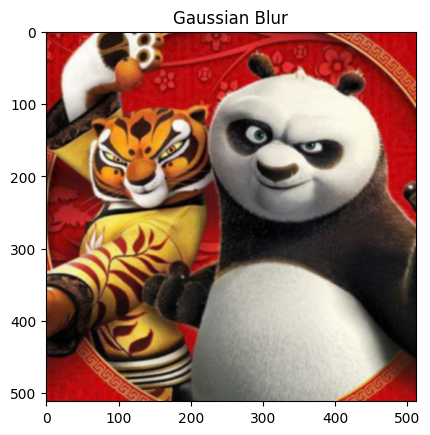

In [ ]:
# Bộ lọc Gauss (Làm mờ)
def gaussian_blur(size, sigma=1.0):
    k = size // 2
    x, y = np.mgrid[-k:k+1, -k:k+1]
    normal = 1 / (2.0 * np.pi * sigma**2)
    g = np.exp(-(x**2 + y**2) / (2 * sigma**2)) * normal
    return g / g.sum()

def convolve(image, kernel):
    ih, iw = image.shape[:2]
    kh, kw = kernel.shape
    pad = kh // 2
    # Pad từng kênh nếu ảnh màu
    if len(image.shape) == 3:
        output = np.zeros_like(image)
        for c in range(3):
            channel = np.pad(image[:, :, c], pad, mode='edge')
            for y in range(ih):
                for x in range(iw):
                    roi = channel[y:y+kh, x:x+kw]
                    output[y, x, c] = np.sum(roi * kernel)
        return output.astype(np.uint8)
    else:
        image_padded = np.pad(image, pad, mode='edge')
        output = np.zeros_like(image)
        for y in range(ih):
            for x in range(iw):
                roi = image_padded[y:y+kh, x:x+kw]
                output[y, x] = np.sum(roi * kernel)
        return output.astype(np.uint8)


image = cv2.imread('/content/panda.jpg')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Áp dụng bộ lọc Gauss
kernel = gaussian_blur(size=5, sigma=1.0)
gaussian_output_rgb = convolve(image_rgb, kernel)

# Hiển thị kết quả
plt.imshow(gaussian_output_rgb)
plt.title("Gaussian Blur")
plt.show()


Bộ lọc Scharr (Phát hiện biên)

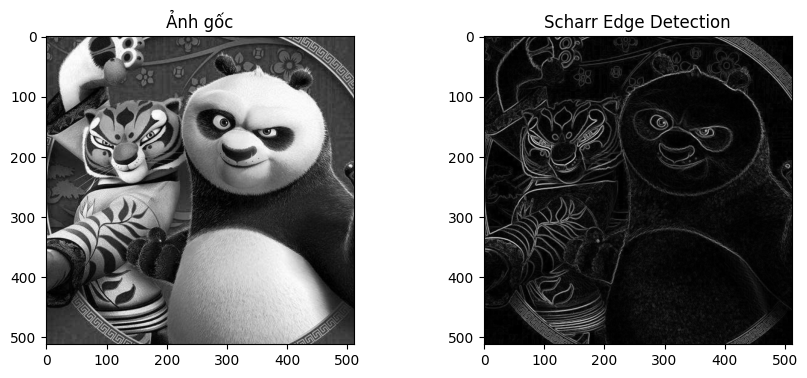

In [ ]:

# Bộ lọc Scharr (Phát hiện biên)
scharrX = np.array([
    [-3, 0, 3],
    [-10, 0, 10],
    [-3, 0, 3]
], dtype="float32")

scharrY = np.array([
    [-3, -10, -3],
    [0, 0, 0],
    [3, 10, 3]
], dtype="float32")

def convolve_gray(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape
    pad = kh // 2
    padded = np.pad(image, pad, mode='edge')
    output = np.zeros((h, w), dtype="float32")

    for y in range(h):
        for x in range(w):
            roi = padded[y:y+kh, x:x+kw]
            output[y, x] = np.sum(roi * kernel)
    return output


# Đọc và chuyển đổi ảnh sang ảnh xám
image = cv2.imread('/content/panda.jpg')
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Áp dụng bộ lọc Scharr
scharr_x = convolve_gray(gray, scharrX)
scharr_y = convolve_gray(gray, scharrY)
scharr_magnitude = np.sqrt(scharr_x**2 + scharr_y**2)
scharr_magnitude = np.clip(scharr_magnitude / scharr_magnitude.max() * 255, 0, 255).astype("uint8")

    # Hiển thị kết quả
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title("Ảnh gốc")


plt.subplot(1,3,2)
plt.imshow(scharr_magnitude, cmap='gray')
plt.title("Scharr Edge Detection")

plt.show()
